In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/CVPR_assignment/Pineapple Leaf disease dataset.zip.zip"
extract_path = "/content/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
import os
import zipfile
import random
import shutil

zip_path = "/content/drive/MyDrive/CVPR_assignment/Pineapple Leaf disease dataset.zip.zip"

dataset_path = "/content/pineapple_dataset"
train_dir = os.path.join(dataset_path, "Train")
test_dir = os.path.join(dataset_path, "Test")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

classes = [
    "Pineapple__leaf_blight",
    "Pineapple_fusarium",
    "Pineapple_healthy",
    "Pineapple_mealybug_wilt"
]

random.seed(42)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    for class_name in classes:

        files = [
            name for name in zip_ref.namelist()
            if f"Pineapple Leaf disease dataset/Pineapple-orginal dataset/{class_name}/" in name
            and name.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        random.shuffle(files)

        split_index = int(len(files) * 0.8)

        train_files = files[:split_index]
        test_files = files[split_index:]

        for folder, file_list in [(train_dir, train_files), (test_dir, test_files)]:

            class_folder = os.path.join(folder, class_name)
            os.makedirs(class_folder, exist_ok=True)

            for file in file_list:
                filename = os.path.basename(file)

                with zip_ref.open(file) as source:
                    with open(os.path.join(class_folder, filename), 'wb') as target:
                        shutil.copyfileobj(source, target)

        print(f"{class_name}: {len(train_files)} training, {len(test_files)} testing")

Pineapple__leaf_blight: 486 training, 122 testing
Pineapple_fusarium: 472 training, 118 testing
Pineapple_healthy: 460 training, 116 testing
Pineapple_mealybug_wilt: 431 training, 108 testing


In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
device

train_dir = Path("/content/pineapple_dataset/Train")
test_dir = Path("/content/pineapple_dataset/Test")

In [15]:
transform = transforms.Compose([
    transforms.Resize((24, 24)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=transform
)

class_names = train_dataset.classes

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Class names:", class_names)
print("Number of classes:", len(class_names))

Training images: 1849
Testing images: 464
Class names: ['Pineapple__leaf_blight', 'Pineapple_fusarium', 'Pineapple_healthy', 'Pineapple_mealybug_wilt']
Number of classes: 4


In [16]:
LEARNING_RATE = 0.001
BATCH = 32
EPOCH = 20


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH,
    shuffle=False
)

In [21]:
class CNNModel(nn.Module):
    def __init__(self, num_classes=4):
        super(CNNModel, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 10, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(10, 35, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(35 * 6 * 6, 30),
            nn.ReLU(),
            nn.Linear(30, 20),
            nn.ReLU(),
            nn.Linear(20, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


model = CNNModel(num_classes=len(class_names)).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

In [22]:
def train_epoch(model, train_loader, optimizer, criterion, device):
    model.train()

    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy

In [23]:
train_accuracies = []

for epoch in range(EPOCH):
    train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    train_accuracies.append(train_acc)

    print("Epoch: {}/{} | Training Accuracy: {:.2f}%".format(epoch+1, EPOCH, train_acc))

Epoch: 1/20 | Training Accuracy: 25.04%
Epoch: 2/20 | Training Accuracy: 40.78%
Epoch: 3/20 | Training Accuracy: 54.95%
Epoch: 4/20 | Training Accuracy: 60.19%
Epoch: 5/20 | Training Accuracy: 63.76%
Epoch: 6/20 | Training Accuracy: 63.87%
Epoch: 7/20 | Training Accuracy: 64.25%
Epoch: 8/20 | Training Accuracy: 64.79%
Epoch: 9/20 | Training Accuracy: 66.79%
Epoch: 10/20 | Training Accuracy: 66.90%
Epoch: 11/20 | Training Accuracy: 67.93%
Epoch: 12/20 | Training Accuracy: 67.39%
Epoch: 13/20 | Training Accuracy: 68.74%
Epoch: 14/20 | Training Accuracy: 69.88%
Epoch: 15/20 | Training Accuracy: 70.04%
Epoch: 16/20 | Training Accuracy: 70.90%
Epoch: 17/20 | Training Accuracy: 71.98%
Epoch: 18/20 | Training Accuracy: 71.07%
Epoch: 19/20 | Training Accuracy: 72.69%
Epoch: 20/20 | Training Accuracy: 75.12%


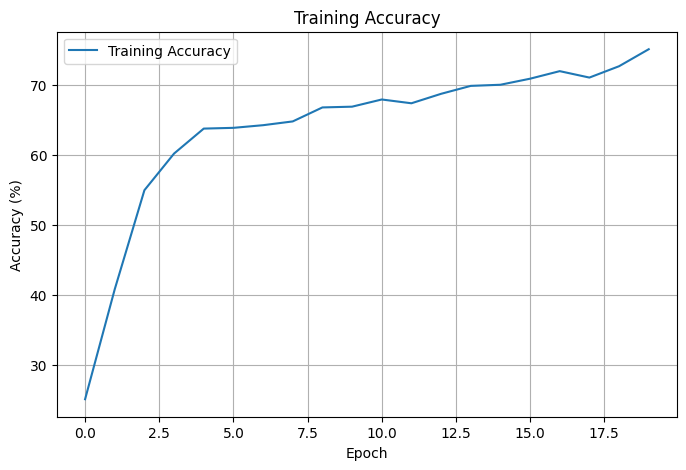

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, label='Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 73.71%
